In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
sns.set_style("whitegrid")

In [5]:
# Load data and convert order_date from text to a real date
df = pd.read_csv("Dataset_clean.csv")
df["order_date"] = pd.to_datetime(df["order_date"])
 

In [6]:
# Helper columns for time analysis
df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month
df["year_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

In [8]:
df.head(2)

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,category,sub_category,product_name,sales,quantity,discount,profit,year,month,year_month
0,7981,CA-2014-103800,2014-01-03,2014-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,2014,1,2014-01-01
1,740,CA-2014-112326,2014-01-04,2014-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717,2014,1,2014-01-01


In [10]:
# ## 1. Sales KPIs


In [11]:
total_sales = df["sales"].sum()
total_profit = df["profit"].sum()
total_orders = df["order_id"].nunique()
total_quantity = df["quantity"].sum()
total_customers = df["customer_id"].nunique()
avg_order_value = total_sales / total_orders
profit_margin = total_profit / total_sales * 100
 
print(f"Total Sales:         ${total_sales:,.0f}")
print(f"Total Profit:        ${total_profit:,.0f}")
print(f"Total Orders:        {total_orders:,}")
print(f"Total Quantity:      {total_quantity:,}")
print(f"Total Customers:     {total_customers:,}")
print(f"Average Order Value: ${avg_order_value:,.2f}")
print(f"Profit Margin:       {profit_margin:.2f}%")
 

Total Sales:         $2,297,201
Total Profit:        $286,397
Total Orders:        5,009
Total Quantity:      37,873
Total Customers:     793
Average Order Value: $458.61
Profit Margin:       12.47%


In [12]:
# Sales, profit and orders per year
yearly = df.groupby("year").agg(
    sales=("sales", "sum"),
    profit=("profit", "sum"),
    orders=("order_id", "nunique"),
)
yearly["margin_%"] = yearly["profit"] / yearly["sales"] * 100
yearly["sales_growth_%"] = yearly["sales"].pct_change() * 100
yearly.round(1)
 

,sales,profit,orders,margin_%,sales_growth_%
year,,,,,
2014,484247.5,49544.0,969,10.2,NaN
2015,470532.5,61618.6,1038,13.1,-2.8
2016,609205.6,81795.2,1315,13.4,29.5
2017,733215.3,93439.3,1687,12.7,20.4


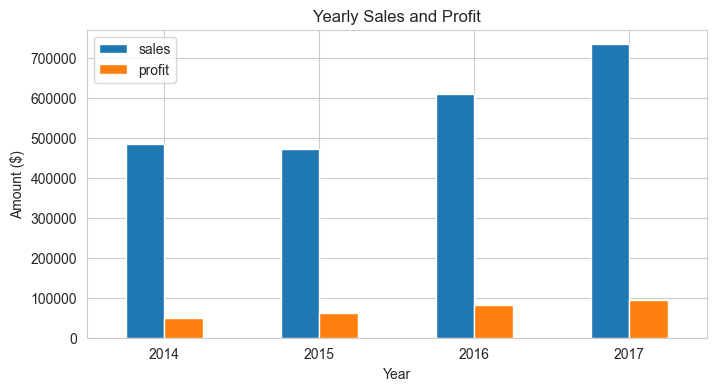

In [14]:
# Are sales and profit growing together?
yearly[["sales", "profit"]].plot(kind="bar", figsize=(8, 4), rot=0)
plt.title("Yearly Sales and Profit")
plt.xlabel("Year")
plt.ylabel("Amount ($)")
plt.ticklabel_format(style="plain", axis="y")
plt.show()

In [15]:
 # ## 2. Time analysis

In [17]:
monthly = df.groupby("year_month").agg(
    sales=("sales", "sum"),
    profit=("profit", "sum"),
    orders=("order_id", "nunique"),
)
monthly.head().round(1)
 

,sales,profit,orders
year_month,,,
2014-01-01,14236.9,2450.2,32
2014-02-01,4519.9,862.3,28
2014-03-01,55691.0,498.7,71
2014-04-01,28295.3,3488.8,66
2014-05-01,23648.3,2738.7,69


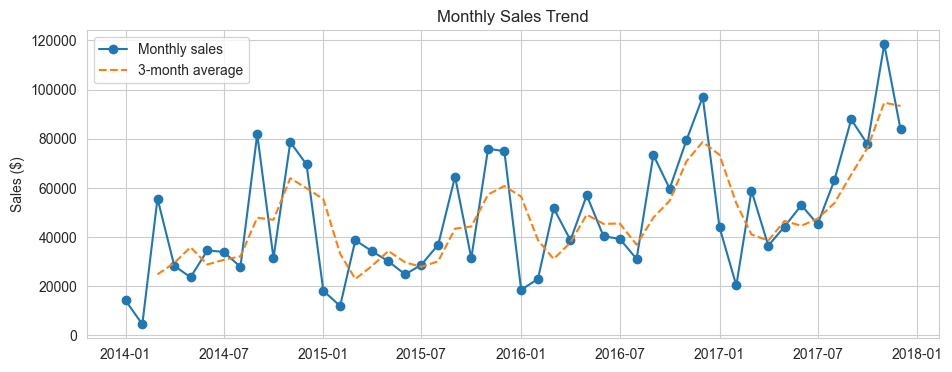

In [19]:
# ### 2.1 Monthly sales trend
 
# Monthly sales with a 3-month average to smooth the noise
plt.figure(figsize=(11, 4))
plt.plot(monthly.index, monthly["sales"], marker="o", label="Monthly sales")
plt.plot(monthly.index, monthly["sales"].rolling(3).mean(), linestyle="--", label="3-month average")
plt.title("Monthly Sales Trend")
plt.ylabel("Sales ($)")
plt.legend()
plt.ticklabel_format(style="plain", axis="y")
plt.show()

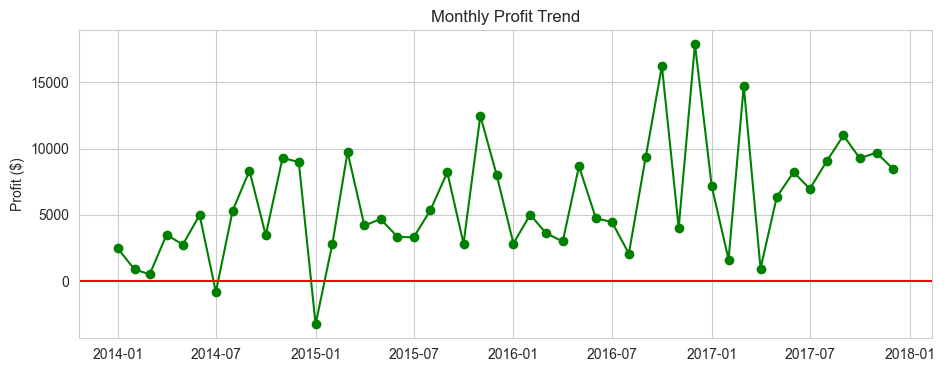

In [20]:
# ### 2.2 Monthly profit trend
 
# Monthly profit; the line at 0 shows loss-making months
plt.figure(figsize=(11, 4))
plt.plot(monthly.index, monthly["profit"], marker="o", color="green")
plt.axhline(0, color="red")
plt.title("Monthly Profit Trend")
plt.ylabel("Profit ($)")
plt.show()

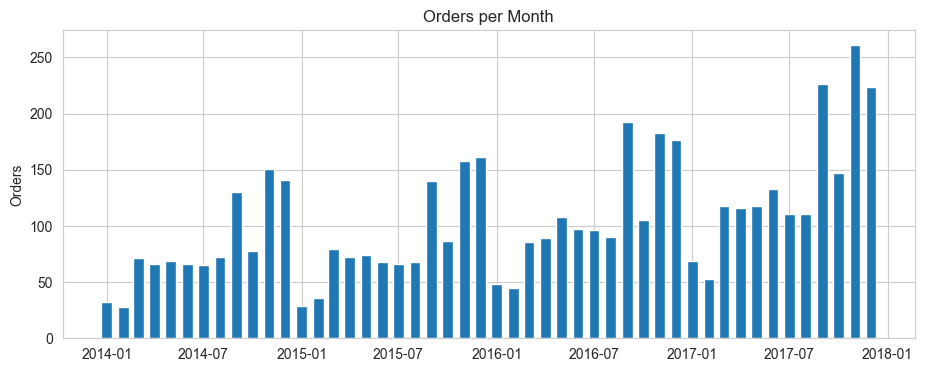

In [23]:
# ### 2.3 Orders per month
 
# Number of orders each month
plt.figure(figsize=(11, 4))
plt.bar(monthly.index, monthly["orders"], width=20)
plt.title("Orders per Month")
plt.ylabel("Orders")
plt.show()

In [25]:
# ### 2.4 Sales vs profit
# Left: both lines together. Right: each dot is a month. If the dots rise left to right, higher sales go with higher profit.

Correlation (sales vs profit): 0.72


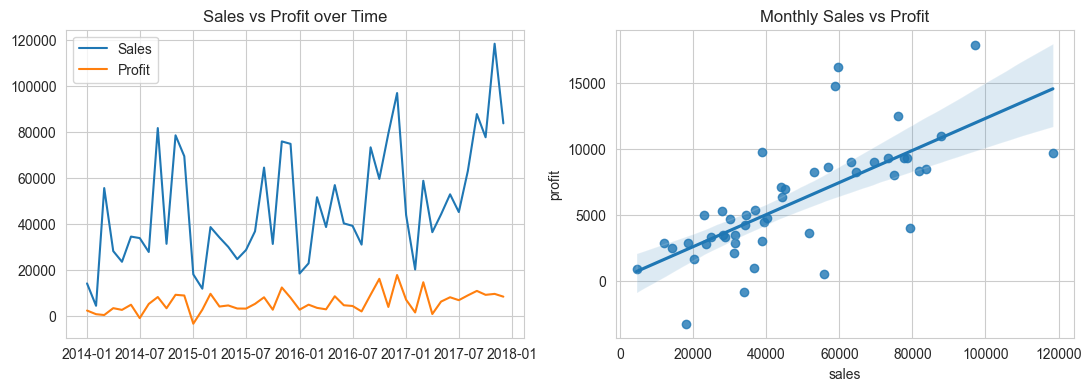

In [26]:
# Correlation between monthly sales and profit
correlation = monthly["sales"].corr(monthly["profit"])
print("Correlation (sales vs profit):", round(correlation, 2))
 
plt.figure(figsize=(13, 4))
 
plt.subplot(1, 2, 1)
plt.plot(monthly.index, monthly["sales"], label="Sales")
plt.plot(monthly.index, monthly["profit"], label="Profit")
plt.title("Sales vs Profit over Time")
plt.legend()
 
plt.subplot(1, 2, 2)
sns.regplot(data=monthly, x="sales", y="profit")
plt.title("Monthly Sales vs Profit")
plt.show()


In [27]:
# ### 2.5 Which months earn the most?
# One line per year. Similar shapes across years mean the pattern is seasonal.

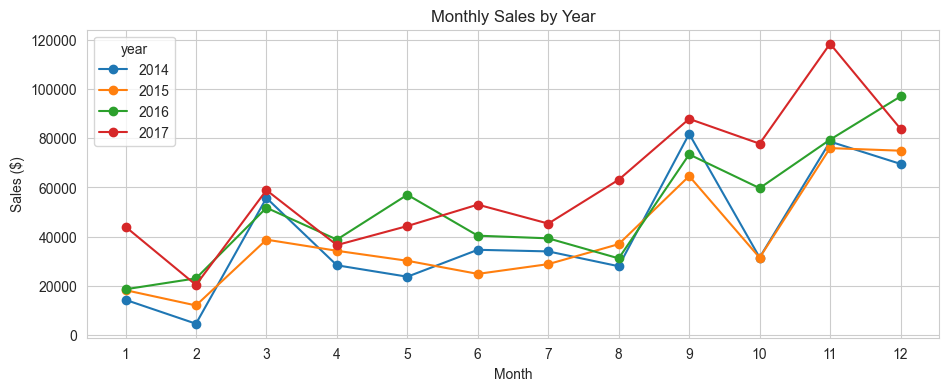

,sales,profit,orders
year_month,,,
2017-11-01,118448.0,9690.0,261
2016-12-01,96999.0,17885.0,176
2017-09-01,87867.0,10992.0,226
2017-12-01,83829.0,8483.0,224
2014-09-01,81777.0,8328.0,130


In [28]:
# Total sales for each calendar month, per year
seasonality = df.pivot_table(index="month", columns="year", values="sales", aggfunc="sum")
 
seasonality.plot(marker="o", figsize=(11, 4))
plt.title("Monthly Sales by Year")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.xticks(range(1, 13))
plt.show()
 
# Top 5 months overall
monthly.sort_values("sales", ascending=False).head(5).round(0)

In [29]:
# ## 3. Product analysis
# **What:** compare categories, sub-categories and products on sales, profit, quantity and discount.
# **Why:** high sales do not always mean high profit.
# **Key business question:** which products or categories generate high sales but weak profit?
 
 

In [30]:
# ### 3.1 Category performance

# Sales, profit and margin by category
category = df.groupby("category").agg(
    sales=("sales", "sum"),
    profit=("profit", "sum"),
    quantity=("quantity", "sum"),
)
category["margin_%"] = category["profit"] / category["sales"] * 100
category.round(1)

,sales,profit,quantity,margin_%
category,,,,
Furniture,741999.8,18451.3,8028,2.5
Office Supplies,719047.0,122490.8,22906,17.0
Technology,836154.0,145454.9,6939,17.4


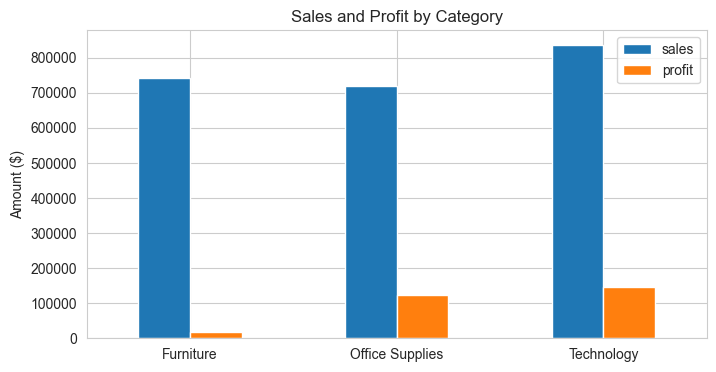

In [31]:
# Sales vs profit by category
category[["sales", "profit"]].plot(kind="bar", figsize=(8, 4), rot=0)
plt.title("Sales and Profit by Category")
plt.xlabel("")
plt.ylabel("Amount ($)")
plt.ticklabel_format(style="plain", axis="y")
plt.show()

In [32]:
# ### 3.2 Sub-category performance

In [36]:
# Sales, profit, quantity and average discount by sub-category
sub = df.groupby("sub_category").agg(
    sales=("sales", "sum"),
    profit=("profit", "sum"),
    quantity=("quantity", "sum"),
    avg_discount=("discount", "mean"),
)
sub["margin_%"] = sub["profit"] / sub["sales"] * 100
sub = sub.sort_values("sales")
sub

,sales,profit,quantity,avg_discount,margin_%
sub_category,,,,,
Fasteners,3024.2800,949.5182,914,0.082028,31.396504
Labels,12486.3120,5546.2540,1400,0.068681,44.418672
Envelopes,16476.4020,6964.1767,906,0.080315,42.267582
Art,27118.7920,6527.7870,3000,0.074874,24.071083
Supplies,46673.5380,-1189.0995,647,0.076842,-2.547695
Paper,78479.2060,34053.5693,5178,0.074891,43.391837
Furnishings,91705.1640,13059.1436,3563,0.138349,14.240358
Appliances,107532.1610,18138.0054,1729,0.166524,16.867517
Bookcases,114879.9963,-3472.5560,868,0.211140,-3.022768


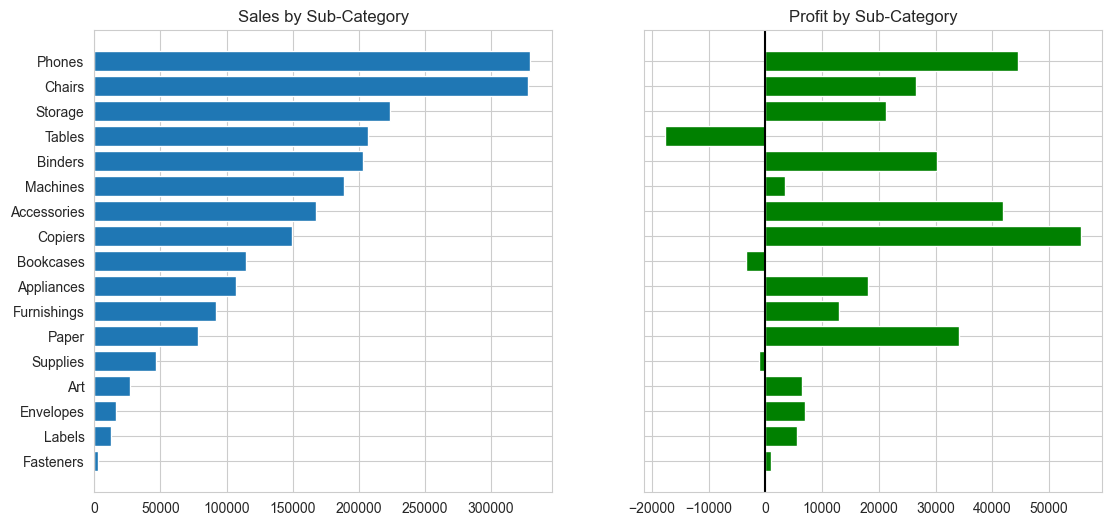

In [37]:
# Sales and profit side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
axes[0].barh(sub.index, sub["sales"])
axes[0].set_title("Sales by Sub-Category")
axes[1].barh(sub.index, sub["profit"], color="green")
axes[1].axvline(0, color="black")
axes[1].set_title("Profit by Sub-Category")
plt.show()

In [38]:
# ### 3.3 High sales but weak profit
# Each dot is a sub-category. **Bottom-right = sells a lot but keeps little (or loses money).**
# Dashed lines show the overall margin and the median sales.
 

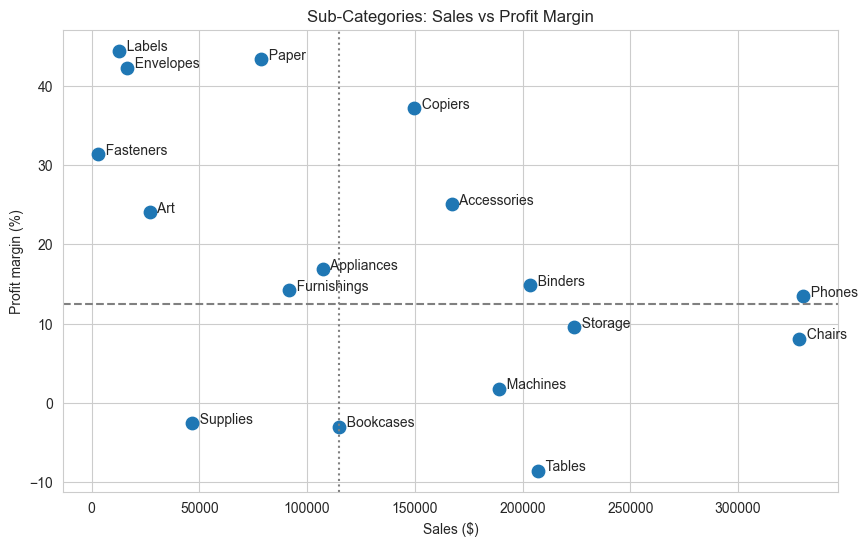

In [39]:
# Sales (x) vs profit margin (y) for every sub-category
median_sales = sub["sales"].median()
 
plt.figure(figsize=(10, 6))
plt.scatter(sub["sales"], sub["margin_%"], s=80)
for name in sub.index:
    plt.text(sub.loc[name, "sales"], sub.loc[name, "margin_%"], "  " + name)
plt.axhline(profit_margin, color="grey", linestyle="--")
plt.axvline(median_sales, color="grey", linestyle=":")
plt.title("Sub-Categories: Sales vs Profit Margin")
plt.xlabel("Sales ($)")
plt.ylabel("Profit margin (%)")
plt.show()

In [40]:
# Sub-categories with above-median sales but below-average margin
sub[(sub["sales"] > median_sales) & (sub["margin_%"] < profit_margin)].round(2)

,sales,profit,quantity,avg_discount,margin_%
sub_category,,,,,
Machines,189238.63,3384.76,440,0.31,1.79
Tables,206965.53,-17725.48,1241,0.26,-8.56
Storage,223843.61,21278.83,3158,0.07,9.51
Chairs,328449.10,26590.17,2356,0.17,8.10


In [41]:
# ### 3.4 Quantity sold

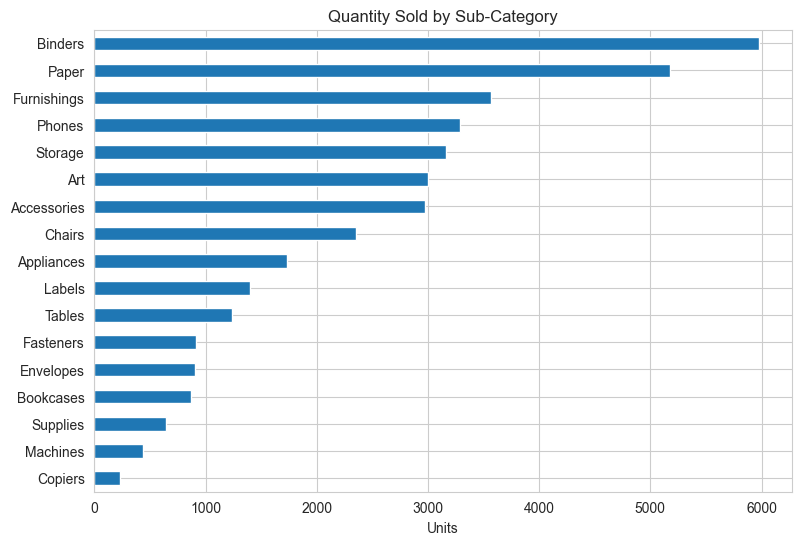

In [42]:
# Units sold by sub-category
sub["quantity"].sort_values().plot(kind="barh", figsize=(9, 6))
plt.title("Quantity Sold by Sub-Category")
plt.xlabel("Units")
plt.ylabel("")
plt.show()
 

In [43]:
# ### 3.5 Top products and loss-making products
# Left: 10 best sellers. Right: 10 products with the lowest total profit.

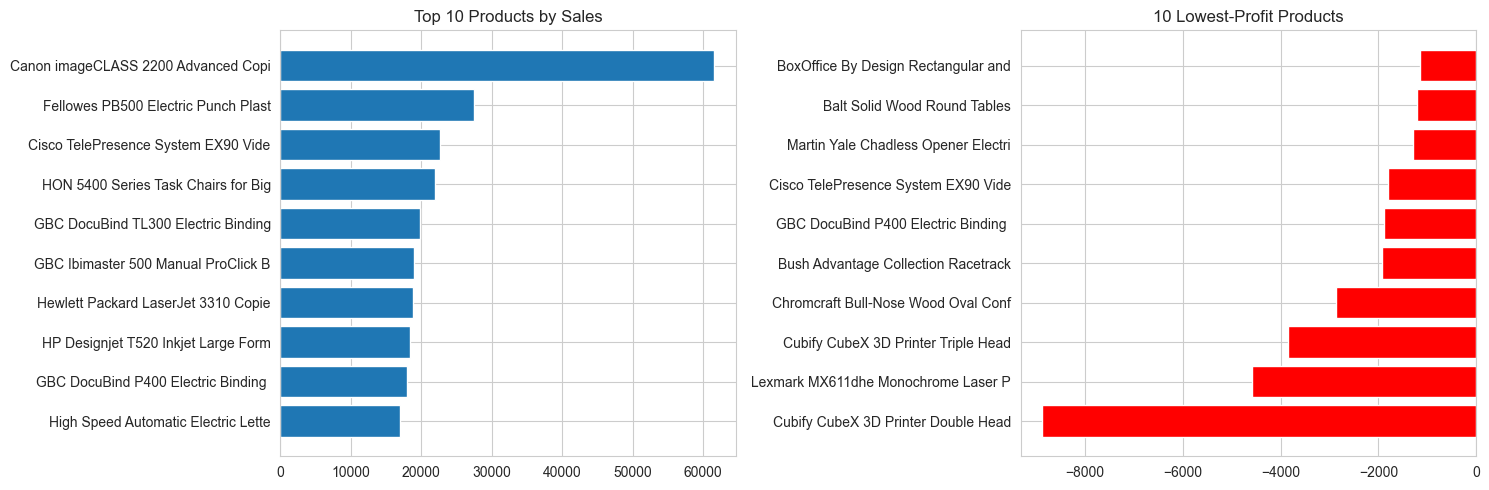

In [46]:
# Total sales and profit per product
products = df.groupby("product_name").agg(sales=("sales", "sum"), profit=("profit", "sum"))
top10_sales = products.sort_values("sales", ascending=False).head(10)
worst10_profit = products.sort_values("profit").head(10)
 
plt.figure(figsize=(15, 5))
 
plt.subplot(1, 2, 1)
plt.barh(top10_sales.index.str[:35], top10_sales["sales"])
plt.gca().invert_yaxis()
plt.title("Top 10 Products by Sales")
 
plt.subplot(1, 2, 2)
plt.barh(worst10_profit.index.str[:35], worst10_profit["profit"], color="red")
plt.title("10 Lowest-Profit Products")
 
plt.tight_layout()
plt.show()

In [47]:
# How many products lose money overall?
loss_products = (products["profit"] < 0).sum()
print(f"{loss_products} of {len(products)} products have negative total profit "
      f"({loss_products / len(products) * 100:.1f}%)")

301 of 1850 products have negative total profit (16.3%)


In [48]:
# ### 3.6 Discount vs profit
# **Why:** discounts raise sales but cut margin. At what discount level do products start losing money?
# Left: average profit per order line. Right: % of order lines that lose money.

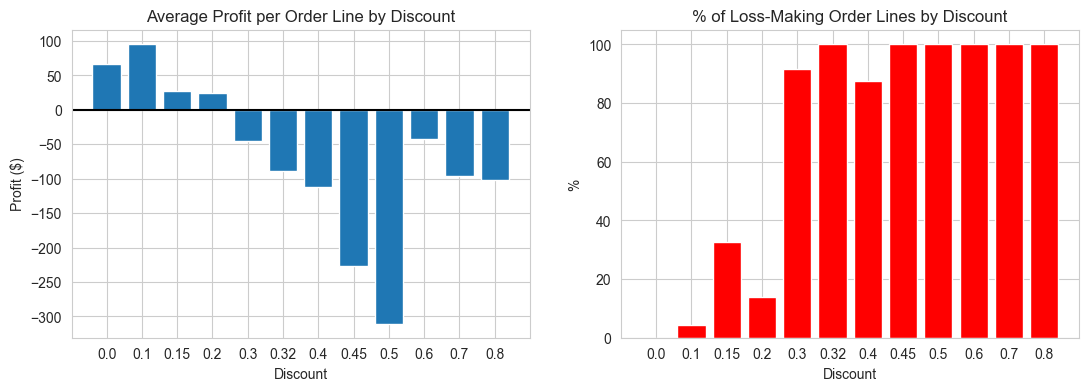

,order_lines,avg_profit,loss_rate
discount,,,
0.00,4798,66.9,0.0
0.10,94,96.1,4.3
0.15,52,27.3,32.7
0.20,3657,24.7,13.7
0.30,227,-45.7,91.6
0.32,27,-88.6,100.0
0.40,206,-111.9,87.4
0.45,11,-226.6,100.0
0.50,66,-310.7,100.0


In [50]:
# Mark each order line as loss-making (True/False)
df["is_loss"] = df["profit"] < 0
 
# Average profit and loss rate at each discount level
discount = df.groupby("discount").agg(
    order_lines=("profit", "size"),
    avg_profit=("profit", "mean"),
    loss_rate=("is_loss", "mean"),
)
discount["loss_rate"] = discount["loss_rate"] * 100
 
plt.figure(figsize=(13, 4))
 
plt.subplot(1, 2, 1)
plt.bar(discount.index.astype(str), discount["avg_profit"])
plt.axhline(0, color="black")
plt.title("Average Profit per Order Line by Discount")
plt.xlabel("Discount")
plt.ylabel("Profit ($)")
 
plt.subplot(1, 2, 2)
plt.bar(discount.index.astype(str), discount["loss_rate"], color="red")
plt.title("% of Loss-Making Order Lines by Discount")
plt.xlabel("Discount")
plt.ylabel("%")
plt.show()
 
discount.round(1)

In [51]:
# ## 4. Regional analysis
# **What:** compare the four regions on sales, profit, orders, customers, AOV and margin.
# **Why:** shows where the business earns the most and where profit is weak.
# **Business question:** which regions are high-revenue, high-profit, or weak-profit?

In [52]:
# All regional metrics in one table
region = df.groupby("region").agg(
    sales=("sales", "sum"),
    profit=("profit", "sum"),
    orders=("order_id", "nunique"),
    customers=("customer_id", "nunique"),
)
region["avg_order_value"] = region["sales"] / region["orders"]
region["margin_%"] = region["profit"] / region["sales"] * 100
region.round(1)

,sales,profit,orders,customers,avg_order_value,margin_%
region,,,,,,
Central,501239.9,39706.4,1175,629,426.6,7.9
East,678781.2,91522.8,1401,674,484.5,13.5
South,391721.9,46749.4,822,512,476.5,11.9
West,725457.8,108418.4,1611,686,450.3,14.9


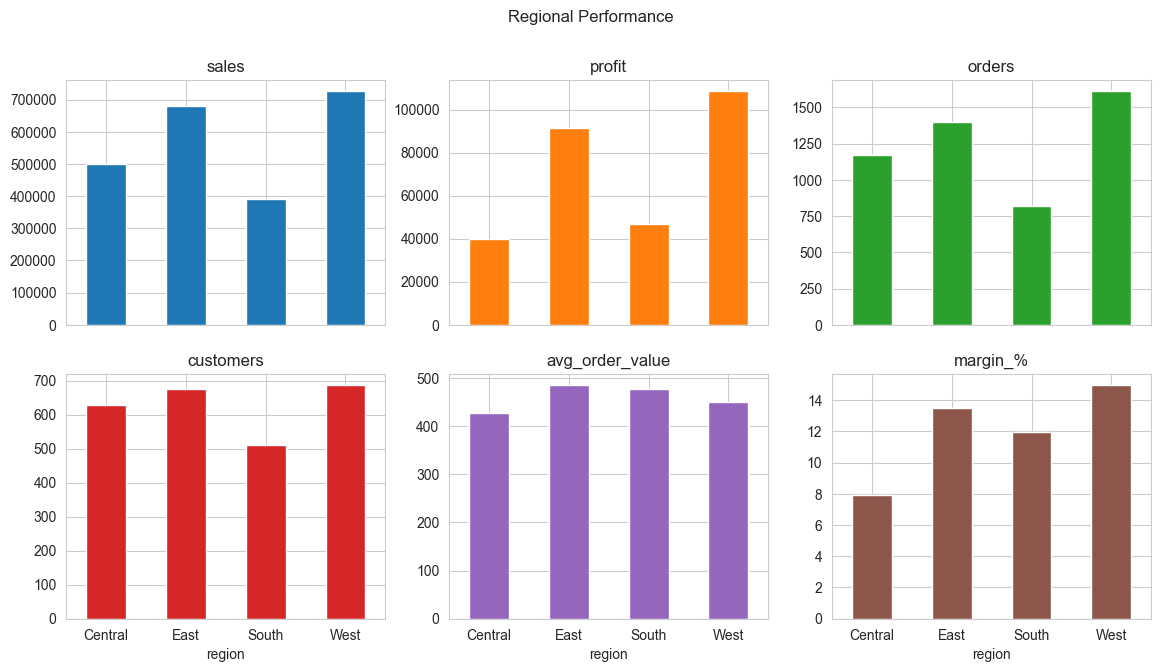

In [53]:
# One small bar chart per metric
region.plot(kind="bar", subplots=True, layout=(2, 3), figsize=(14, 7), legend=False, rot=0)
plt.suptitle("Regional Performance")
plt.show()

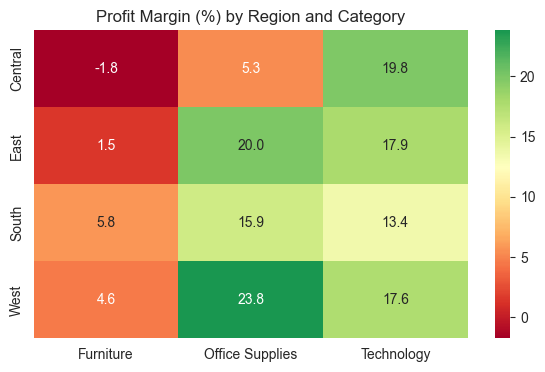

In [54]:
# Profit margin for each region and category
region_category = df.groupby(["region", "category"])[["sales", "profit"]].sum()
region_category["margin_%"] = region_category["profit"] / region_category["sales"] * 100
 
plt.figure(figsize=(7, 4))
sns.heatmap(region_category["margin_%"].unstack(), annot=True, fmt=".1f", cmap="RdYlGn", center=profit_margin)
plt.title("Profit Margin (%) by Region and Category")
plt.xlabel("")
plt.ylabel("")
plt.show()
 

In [ ]:
#Connecting to SQL Database

In [1]:
import getpass
 
import pandas as pd
import pymysql
 
# ---- Settings: change these if yours are different ----
HOST = "localhost"
PORT = 3306
USER = "root"
DATABASE = "Retail_Analysis"
CSV_PATH = "Dataset_clean.csv"
 
CREATE_TABLE = """
CREATE TABLE transactions (
    row_id        INT,
    order_id      VARCHAR(20),
    order_date    DATE,
    ship_date     DATE,
    ship_mode     VARCHAR(20),
    customer_id   VARCHAR(15),
    customer_name VARCHAR(50),
    segment       VARCHAR(20),
    country       VARCHAR(30),
    city          VARCHAR(50),
    state         VARCHAR(30),
    postal_code   INT,
    region        VARCHAR(10),
    product_id    VARCHAR(20),
    category      VARCHAR(30),
    sub_category  VARCHAR(30),
    product_name  VARCHAR(255),
    sales         DECIMAL(12,4),
    quantity      INT,
    discount      DECIMAL(4,2),
    profit        DECIMAL(12,4)
)
"""
 
# Read the CSV (UTF-8, so accents and quotes load correctly)
df = pd.read_csv(CSV_PATH, encoding="utf-8")
print("Rows in CSV:", len(df))
 
# Connect to MySQL (password is typed here, not saved in the file)
password = getpass.getpass(f"MySQL password for {USER}: ")
connection = pymysql.connect(host=HOST, port=PORT, user=USER, password=password, charset="utf8mb4")
cursor = connection.cursor()
 
# Create the database and a fresh table
cursor.execute(f"CREATE DATABASE IF NOT EXISTS `{DATABASE}`")
cursor.execute(f"USE `{DATABASE}`")
cursor.execute("DROP TABLE IF EXISTS transactions")
cursor.execute(CREATE_TABLE)
 
# Insert the rows in batches of 1,000
columns = ", ".join(df.columns)
placeholders = ", ".join(["%s"] * len(df.columns))
insert_sql = f"INSERT INTO transactions ({columns}) VALUES ({placeholders})"
rows = df.astype(object).values.tolist()
 
for start in range(0, len(rows), 1000):
    cursor.executemany(insert_sql, rows[start:start + 1000])
    print(f"Inserted {min(start + 1000, len(rows))} / {len(rows)}")
connection.commit()
 
# Check the load: expect 9994 rows, 5009 orders, 793 customers
cursor.execute(
    "SELECT COUNT(*), COUNT(DISTINCT order_id), COUNT(DISTINCT customer_id), ROUND(SUM(sales), 0) "
    "FROM transactions"
)
print("rows, orders, customers, total sales:", cursor.fetchone())
connection.close()
 

Rows in CSV: 9994


MySQL password for root:  ········


Inserted 1000 / 9994
Inserted 2000 / 9994
Inserted 3000 / 9994
Inserted 4000 / 9994
Inserted 5000 / 9994
Inserted 6000 / 9994
Inserted 7000 / 9994
Inserted 8000 / 9994
Inserted 9000 / 9994
Inserted 9994 / 9994
rows, orders, customers, total sales: (9994, 5009, 793, Decimal('2297201'))
